# Exercise 4.4 | The Problem of Timeseries

**Okun's Law**: when unemployment rises, GDP tends to fall. We'll estimate this relationship with four different models, checking each one for autocorrelation: residuals that are related to the residual of the period before.

The data are quarterly observations for the United States from 1948 through 2019. The outcome is **gdp**, real GDP in billions of dollars, and the predictor is **unemployment**, the unemployment rate in percentage points. Complete the notebook, then enter your answers in Gradescope.

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

# File Path
file_path = 'https://econ-0150.tayweid.io/data/'

The rows are in time order, one per quarter. We keep the date, GDP, and the unemployment rate, and build every other variable ourselves.

In [2]:
# Load Data
data = pd.read_csv(file_path + 'okun.csv', index_col=0)
# Keep the date and the two series
data = data[['observation_date', 'gdp', 'unemployment']]
# Display header
data.head()

,observation_date,gdp,unemployment
1,1948-04-01,2276.690,3.9
2,1948-07-01,2289.770,3.6
3,1948-10-01,2292.364,3.7
4,1949-01-01,2260.807,4.3
5,1949-04-01,2253.128,5.3


## Explore the Data

**Question 1.** Plot `gdp` over time and `unemployment` over time. How does each series move over these seven decades?

*Hint: `data['gdp'].plot()` in one cell and `data['unemployment'].plot()` in another. The x-axis is the row number, which counts quarters.*

<Axes: >

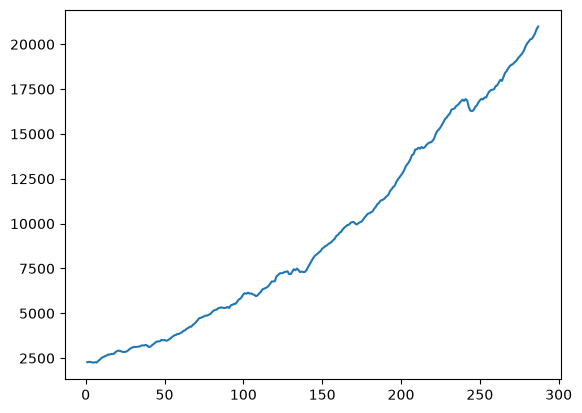

In [3]:
data['gdp'].plot()

<Axes: >

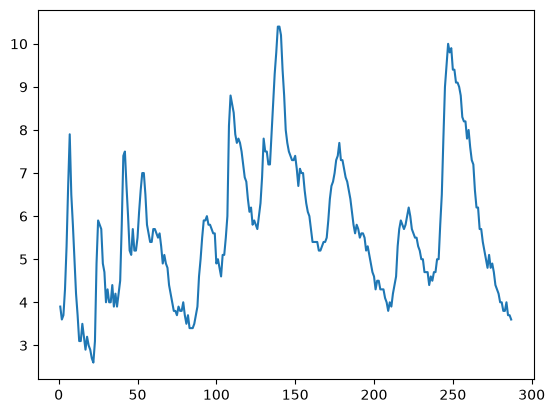

In [4]:
data['unemployment'].plot()

GDP grows while unemployment fluctuates around a stable mean.

## Model 1 | Levels

The standard approach puts the two series straight into the model:

$$GDP_t = \beta_0 + \beta_1 \cdot Unemployment_t + \epsilon_t$$

**Question 2.** Fit the levels model and print the coefficient table. What is the estimated slope? Does its sign agree with Okun's Law?

*Hint: save `smf.ols('gdp ~ unemployment', data=data).fit()` as `model1`, then use `print(model1.summary().tables[1])`.*

In [5]:
# 1. Fit the levels model
model1 = smf.ols('gdp ~ unemployment', data=data).fit()
print(model1.summary().tables[1])

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept     6707.7410   1179.511      5.687      0.000    4386.083    9029.399
unemployment   479.6492    197.436      2.429      0.016      91.032     868.266


{++The estimated slope is 479.649.++} The estimated coefficient on `unemployment` is positive, which suggests that higher unemployment is associated with higher GDP. {++No:++} Okun's Law predicts a negative relationship.

**Question 3.** Make a residual plot and a lagged residual plot for `model1`. Then calculate the correlation between each residual and the residual of the quarter before. What do the plots and the correlation tell you about this model?

*Hint: the residual plot is `plt.scatter(model1.predict(), model1.resid)`. For the lag plot, save `model1.resid.values[:-1]` as `lagged_residuals` and `model1.resid.values[1:]` as `current_residuals`, then use `plt.scatter(lagged_residuals, current_residuals)`. The correlation is `np.corrcoef(lagged_residuals, current_residuals)[0, 1]`.*

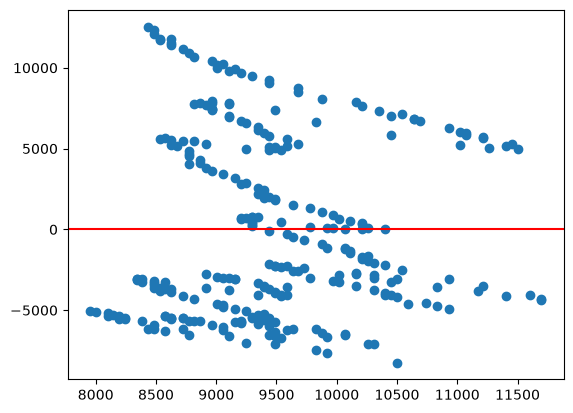

In [6]:
# 2. Residual plot
plt.scatter(model1.predict(), model1.resid)
plt.axhline(0, color='red')

0.9989949031204582


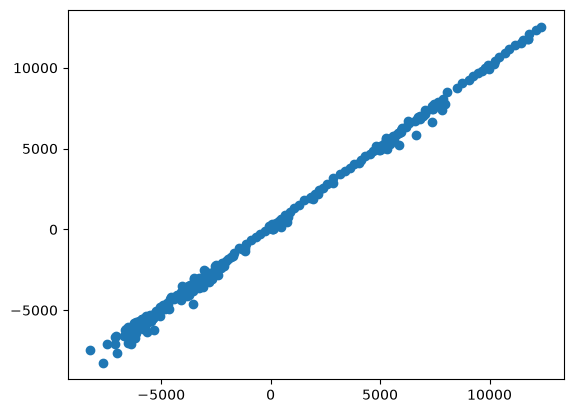

In [7]:
# 3. Lagged residual plot
lagged_residuals = model1.resid.values[:-1]
current_residuals = model1.resid.values[1:]
plt.scatter(lagged_residuals, current_residuals)

# Lagged residual correlation
print(np.corrcoef(lagged_residuals, current_residuals)[0, 1])

{++The residual plot shows a clear non-random pattern, and the lagged residual plot shows strong positive autocorrelation: the correlation is 0.999.++} This means the residuals are not independent across time periods. We cannot trust the reported p-values.

## Model 2 | First Differences (Y)

We can reduce autocorrelation by modeling the *change* in GDP from one quarter to the next instead of its level:

$$\Delta GDP_t = GDP_t - GDP_{t-1}$$

In [8]:
# Create first differences of Y
data['gdp_diff'] = data['gdp'].diff()
data = data.dropna()

**Question 4.** Fit the model `gdp_diff ~ unemployment` and save it as `model2`. Make the lagged residual plot and calculate the lagged residual correlation as in Question 3. How does the correlation compare with Model 1?

In [9]:
# Step 2. Fit the model (Y differenced, X in levels)
model2 = smf.ols('gdp_diff ~ unemployment', data=data).fit()
print(model2.summary().tables[1])

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       60.5454     16.225      3.732      0.000      28.609      92.481
unemployment     0.8467      2.713      0.312      0.755      -4.494       6.187


0.42406017206448415


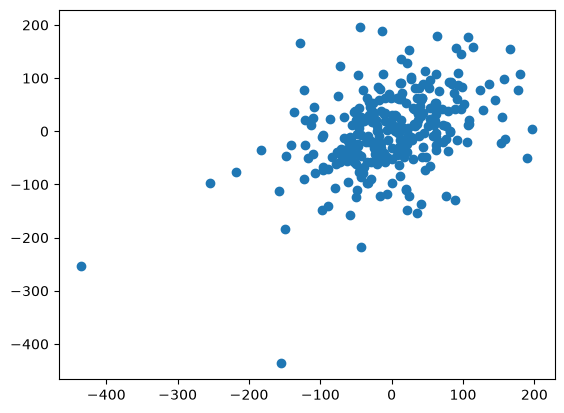

In [10]:
# Lagged residual plot
lagged_residuals = model2.resid.values[:-1]
current_residuals = model2.resid.values[1:]
plt.scatter(lagged_residuals, current_residuals)

# Lagged residual correlation
print(np.corrcoef(lagged_residuals, current_residuals)[0, 1])

{++The correlation is 0.424, down from 0.999 in Model 1.++} First differences reduces but does not eliminate the problem of autocorrelation.

## Model 3 | First Differences (X, Y)

Model 2 compares the *change* in GDP with the *level* of unemployment. Okun's Law is about changes in both:

$$\Delta GDP_t = \beta_0 + \beta_1 \cdot \Delta Unemployment_t + \epsilon_t$$

In [11]:
# Create first differences of X
data['unemployment_diff'] = data['unemployment'].diff()
data = data.dropna()

**Question 5.** Fit the model `gdp_diff ~ unemployment_diff` and save it as `model3`. Calculate the lagged residual correlation. What are the estimated intercept and slope? Interpret each one in context. Does the sign of the slope agree with Okun's Law now?

In [12]:
# Step 2. Fit the double differences model (both X and Y differenced)
model3 = smf.ols('gdp_diff ~ unemployment_diff', data=data).fit()
print(model3.summary().tables[1])

                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            65.5989      3.969     16.528      0.000      57.787      73.411
unemployment_diff   -80.2505      9.335     -8.597      0.000     -98.625     -61.876


In [13]:
# Lagged residuals
lagged_residuals = model3.resid.values[:-1]
current_residuals = model3.resid.values[1:]

# Lagged residual correlation
print(np.corrcoef(lagged_residuals, current_residuals)[0, 1])

0.2560845867330536


{++The lagged residual correlation is 0.256. The estimated intercept is 65.599 and the estimated slope is -80.251.++}

{++The intercept: in a quarter when the unemployment rate does not change, GDP rises by about \$65.6 billion on average. The slope: a one percentage point rise in the unemployment rate over a quarter is associated with a change in GDP that is about \$80.3 billion lower.++}

{++Yes. The slope is now negative, which agrees with Okun's Law.++}

## Model 4 | Growth Rates

GDP grows exponentially, so a \$65 billion change means something very different in 1950 than in 2019. Growth rates put every quarter on the same scale:

$$g_{GDP,t} = \beta_0 + \beta_1 \cdot g_{Unemployment,t} + \epsilon_t$$

In [14]:
# Calculate growth rates (0.01 is growth of 1 percent)
data['gdp_growth'] = data['gdp'].pct_change()
data['unemployment_growth'] = data['unemployment'].pct_change()
data = data.dropna()

**Question 6.** Fit the model `gdp_growth ~ unemployment_growth` and save it as `model4`. Calculate the lagged residual correlation. What does the intercept say about GDP growth in a quarter when the unemployment rate does not change?

In [15]:
# Step 3. Fit the growth rate model
model4 = smf.ols('gdp_growth ~ unemployment_growth', data=data).fit()
print(model4.summary().tables[1])

                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               0.0081      0.000     17.414      0.000       0.007       0.009
unemployment_growth    -0.0644      0.006    -11.321      0.000      -0.076      -0.053


In [16]:
# Lagged residuals
lagged_residuals = model4.resid.values[:-1]
current_residuals = model4.resid.values[1:]

# Lagged residual correlation
print(np.corrcoef(lagged_residuals, current_residuals)[0, 1])

0.13364430941924066


{++The lagged residual correlation is 0.134. The intercept is 0.0081: GDP grows by about 0.81 percent in a quarter when the unemployment rate does not change.++}

## Comparing the Models

**Question 7.** Compare the lagged residual correlations from the four models. Which model has the least autocorrelation? Did differencing or growth rates eliminate it?

{++The correlations are 0.999 (Model 1), 0.424 (Model 2), 0.256 (Model 3), and 0.134 (Model 4). Model 4, growth rates, has the least autocorrelation. No:++} Differencing reduces autocorrelation but rarely eliminates it entirely.

**Question 8.** Plot Okun's Law: make a scatter plot with `unemployment_diff` on the x-axis and `gdp_growth` on the y-axis, with the regression line overlaid. Describe the relationship in one sentence.

*Hint: `sns.regplot(data=data, x='unemployment_diff', y='gdp_growth', ci=None)`.*

<Axes: xlabel='unemployment_diff', ylabel='gdp_growth'>

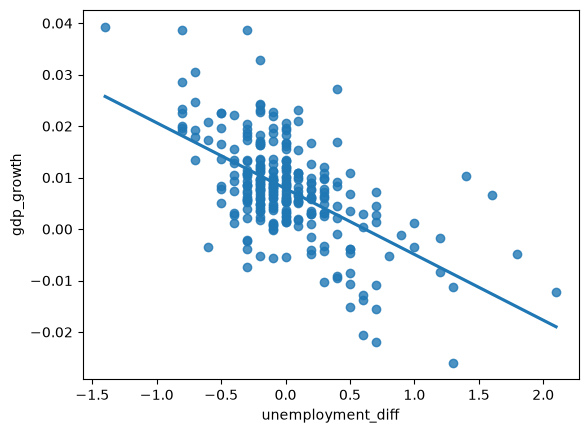

In [17]:
sns.regplot(data=data, x='unemployment_diff', y='gdp_growth', ci=None)

{++The relationship is negative:++} when unemployment rises, GDP growth slows.